# 02 · Tasmania at 17 km: testing and using BARPA-R

**BARPA-R regional climate model · driven by ERA5 and by CESM2 r11 · daily maximum temperature (`tasmax`) · 1970–2100**

Notebook 01 used the CESM2 global model, whose ~100 km grid stops at 39°S and would cover Tasmania with only six land cells. This notebook uses **BARPA-R**, the Bureau of Meteorology's regional climate model. BARPA-R re-simulates Australia on a ~17 km grid, taking its large-scale weather from a global model at the edges of its domain.

It does two things, in this order:

1. **Tests the model against observations (1985–2014).** BARPA-R is published as a research product, and its evaluation paper reports a cold bias in daily maximum temperature across southern Australia. Before using its projections, we measure that bias over Tasmania.
2. **Projects heat hazard** under a low-emissions scenario (SSP1-2.6) and a high-emissions one (SSP3-7.0), with an emphasis on measures that are robust to the bias found in step 1.

| Dataset | What it is | Role here | Years |
|---|---|---|---|
| AGCD v1.0.3 | Station observations interpolated to a 0.05° (~5 km) grid | The observed reference | 1985–2014 |
| BARPA-R ← ERA5 | The regional model driven by ERA5, a reanalysis (observations blended with a weather model) | Isolates the regional model's own errors | 1985–2014 |
| BARPA-R ← CESM2 r11 | The same regional model driven by CESM2 member r11, the same run as notebook 01's SSP3-7.0 data | Historical baseline and projections | 1970–2100 |

The difference between the two BARPA-R runs shows how much error the global model adds on top of the regional model's own.

> Data come from NCI's public THREDDS server. Run `python scripts/download_tasmania.py` first (about 15 minutes, ~1 GB). See `data/README.md` for sources, licences and citations.

In [1]:
import sys
import warnings
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib.colors import LinearSegmentedColormap

sys.path.insert(0, str(Path.cwd().parent / "src"))  # use the local package without installing it
import heatrisk as hr

warnings.filterwarnings("ignore", message="All-NaN slice")  # ocean cells have no data

DATA_DIR = Path("../data/raw/tasmania")
FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)

BASELINE = "1985–2014"
WINDOWS = {
    "1985–2014": (1985, 2014),
    "2021–2050": (2021, 2050),
    "2041–2070": (2041, 2070),
    "2071–2100": (2071, 2100),
}
FUTURE = [name for name in WINDOWS if name != BASELINE]
SCENARIOS = {"SSP1-2.6": "cesm2_ssp126", "SSP3-7.0": "cesm2_ssp370"}

# Reference places: the nearest ~17 km land cell that also has observations.
PLACES = {
    "Hobart": (-42.88, 147.33),
    "Launceston": (-41.44, 147.14),
    "Strahan (west coast)": (-42.15, 145.33),
    "Central Plateau (Liawenee)": (-41.90, 146.67),
}

INK, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SCENARIO_COLOURS = {"SSP1-2.6": "#2a78d6", "SSP3-7.0": "#eb6834"}
BIAS_CMAP = LinearSegmentedColormap.from_list(
    "bias", ["#104281", "#3987e5", "#cde2fb", "#f0efec", "#fbd5c8", "#e34948", "#8a1f1f"]
)
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.titlelocation": "left",
    "axes.edgecolor": INK_MUTED,
    "axes.labelcolor": INK,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "grid.color": GRID,
    "lines.linewidth": 1.5,
})
MAP_EXTENT = [143.7, 148.6, -43.8, -39.5]


def map_panel(ax, title):
    ax.set_extent(MAP_EXTENT, crs=ccrs.PlateCarree())
    ax.coastlines("10m", linewidth=0.6, color=INK_MUTED)
    ax.set_title(title)


def window(da, name):
    start, end = WINDOWS[name]
    return da.sel(time=slice(str(start), str(end)))

## 1 · Load the data

BARPA-R temperatures are converted from kelvin to °C. Both CESM2-driven scenarios continue the same historical run (r11), so, unlike in notebook 01, nothing is spliced together. Land cells are those that BARPA-R itself treats as more than 50% land.

AGCD's interpolated surface also extends over the sea, so its ocean cells are removed with a detailed (1:10 million) coastline. The observations are then averaged from their 5 km grid onto BARPA-R's 17 km cells (`heatrisk.block_mean`). This is a fair comparison: a model cell represents an area average, not a point. Coastal cells with less than half their area observed are dropped.

In [2]:
def load_barpa(name):
    path = next(DATA_DIR.glob(f"barpa_{name}_tasmax_*.nc"))
    tasmax = xr.open_dataset(path)["tasmax"].load() - 273.15
    tasmax.attrs["units"] = "°C"
    return tasmax

era5_run = load_barpa("era5_evaluation")
historical = load_barpa("cesm2_historical")
scenario_runs = {scen: load_barpa(name) for scen, name in SCENARIOS.items()}
cesm2_runs = {scen: xr.concat([historical, run], dim="time") for scen, run in scenario_runs.items()}

land = xr.open_dataset(DATA_DIR / "barpa_sftlf.nc")["sftlf"] > 50
orography = xr.open_dataset(DATA_DIR / "barpa_orog.nc")["orog"]

# All BARPA-R runs share one grid; guard against tiny rounding differences in the stored coordinates.
assert np.allclose(era5_run.lat, historical.lat) and np.allclose(era5_run.lon, historical.lon)
era5_run = era5_run.assign_coords(lat=historical.lat, lon=historical.lon)

observed_5km = xr.open_dataset(DATA_DIR / "agcd_tmax_1985-2014.nc")["tmax"].load()
# AGCD's interpolation also fills the sea; those values are not observations.
observed_5km = observed_5km.where(hr.land_mask(observed_5km.lat, observed_5km.lon, resolution="10m"))
observed = hr.block_mean(observed_5km, historical.lat, historical.lon)

compare = land & observed.notnull().any("time")
print(f"BARPA-R grid over the box: {historical.sizes['lat']} × {historical.sizes['lon']} cells, "
      f"{int(land.sum())} land cells, {int(compare.sum())} with observations")
print(f"CESM2-driven: {str(historical.time[0].values)[:10]} to {str(cesm2_runs['SSP3-7.0'].time[-1].values)[:10]}")

BARPA-R grid over the box: 30 × 36 cells, 303 land cells, 297 with observations
CESM2-driven: 1970-01-01 to 2100-12-31


## 2 · Tasmania at three resolutions

The left panel shows what notebook 01's global model sees: six land cells, each about 100 km across. BARPA-R (middle) resolves the Central Plateau, the western ranges and the major valleys. The observations (right) show the summer temperature pattern these features create: warm in the north-east and Derwent valley, cool on the plateau and the wet west coast.

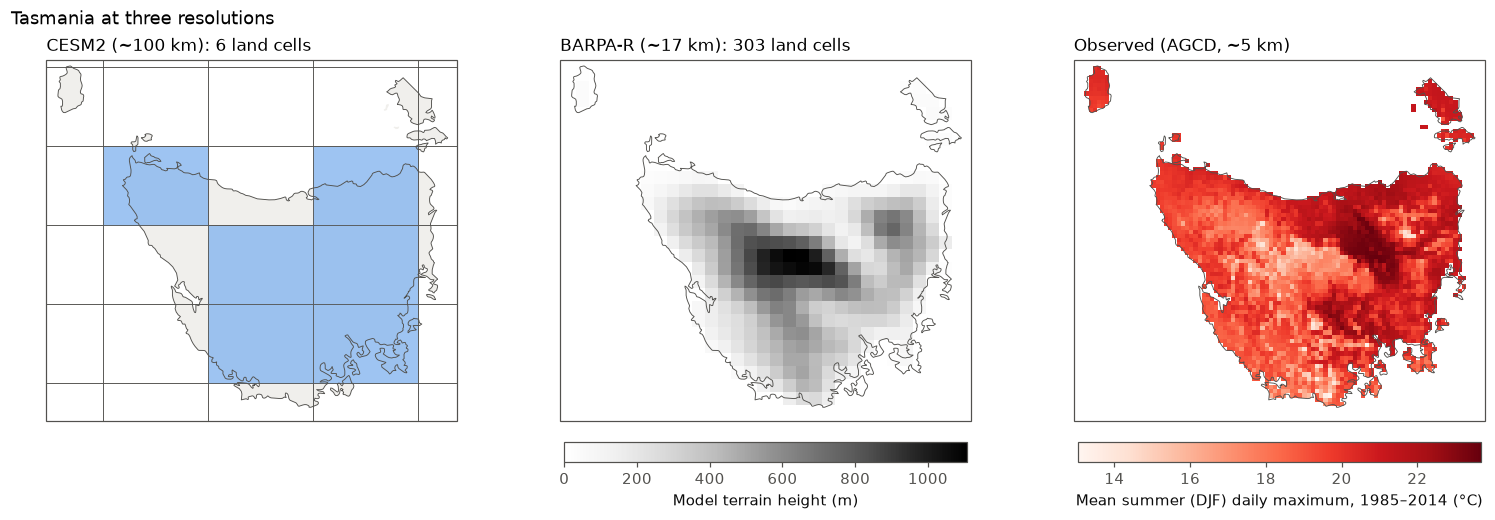

In [3]:
# CESM2's native grid (0.9375° × 1.25°), as used in notebook 01.
cesm2_lat = np.linspace(-90, 90, 192)
cesm2_lon = np.arange(288) * 1.25
cesm2_land = hr.land_mask(cesm2_lat[(cesm2_lat > -45) & (cesm2_lat < -39)],
                          cesm2_lon[(cesm2_lon > 142) & (cesm2_lon < 150)])
lat_edges, lon_edges = hr.cell_edges(cesm2_land.lat), hr.cell_edges(cesm2_land.lon)

observed_summer = observed_5km.sel(time=observed_5km.time.dt.season == "DJF").mean("time")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), subplot_kw={"projection": ccrs.PlateCarree()},
                         layout="constrained")
ax = axes[0]
ax.add_feature(cfeature.LAND.with_scale("10m"), facecolor="#f0efec")
for i, lat in enumerate(cesm2_land.lat.values):
    for j, lon in enumerate(cesm2_land.lon.values):
        is_land = bool(cesm2_land[i, j])
        ax.add_patch(mpatches.Rectangle(
            (lon_edges[j], lat_edges[i]), lon_edges[j + 1] - lon_edges[j], lat_edges[i + 1] - lat_edges[i],
            transform=ccrs.PlateCarree(), facecolor="#86b6ef" if is_land else "none",
            edgecolor=INK_MUTED, linewidth=0.6, alpha=0.8))
map_panel(ax, f"CESM2 (~100 km): {int(cesm2_land.sum())} land cells")

mesh = axes[1].pcolormesh(orography.lon, orography.lat, orography.where(land), transform=ccrs.PlateCarree(),
                          cmap="Greys", vmin=0, shading="auto")
map_panel(axes[1], f"BARPA-R (~17 km): {int(land.sum())} land cells")
fig.colorbar(mesh, ax=axes[1], orientation="horizontal", shrink=0.8, label="Model terrain height (m)")

mesh = axes[2].pcolormesh(observed_summer.lon, observed_summer.lat, observed_summer,
                          transform=ccrs.PlateCarree(), cmap="Reds", shading="auto")
map_panel(axes[2], "Observed (AGCD, ~5 km)")
fig.colorbar(mesh, ax=axes[2], orientation="horizontal", shrink=0.8,
             label=f"Mean summer (DJF) daily maximum, {BASELINE} (°C)")
fig.suptitle("Tasmania at three resolutions", x=0.01, ha="left", fontsize=12)
fig.savefig(FIG_DIR / "06_tasmania_resolution.png")
plt.show()

## 3 · Does BARPA-R get Tasmania's present-day heat right?

Four measures of daily maximum temperature are compared over 1985–2014: summer and winter means, the 95th percentile of all days, and the average hottest day of each year (TXx). Bias means model minus observations.

In [4]:
def heat_measures(tasmax):
    base = window(tasmax, BASELINE)
    season = base.time.dt.season
    return {
        "Summer (DJF) mean": base.sel(time=season == "DJF").mean("time"),
        "Winter (JJA) mean": base.sel(time=season == "JJA").mean("time"),
        "95th percentile": base.quantile(0.95, dim="time").drop_vars("quantile"),
        "Hottest day of the year (TXx)": hr.annual_maximum(base).mean("time"),
    }

measures = {
    "Observed": heat_measures(observed),
    "BARPA-R ← ERA5": heat_measures(era5_run),
    "BARPA-R ← CESM2": heat_measures(historical),
}

rows = {}
for name in measures["Observed"]:
    obs_value = measures["Observed"][name]
    rows[name] = {
        "Observed (°C)": float(hr.regional_mean(obs_value, compare)),
        "Bias, ERA5-driven (°C)": float(hr.regional_mean(measures["BARPA-R ← ERA5"][name] - obs_value, compare)),
        "Bias, CESM2-driven (°C)": float(hr.regional_mean(measures["BARPA-R ← CESM2"][name] - obs_value, compare)),
    }
evaluation = pd.DataFrame(rows).T
evaluation.round(2)

,Observed (°C),"Bias, ERA5-driven (°C)","Bias, CESM2-driven (°C)"
Summer (DJF) mean,19.76,-1.43,-2.00
Winter (JJA) mean,10.49,-1.15,-2.41
95th percentile,23.84,-1.15,-1.94
Hottest day of the year (TXx),30.72,-1.65,-2.17


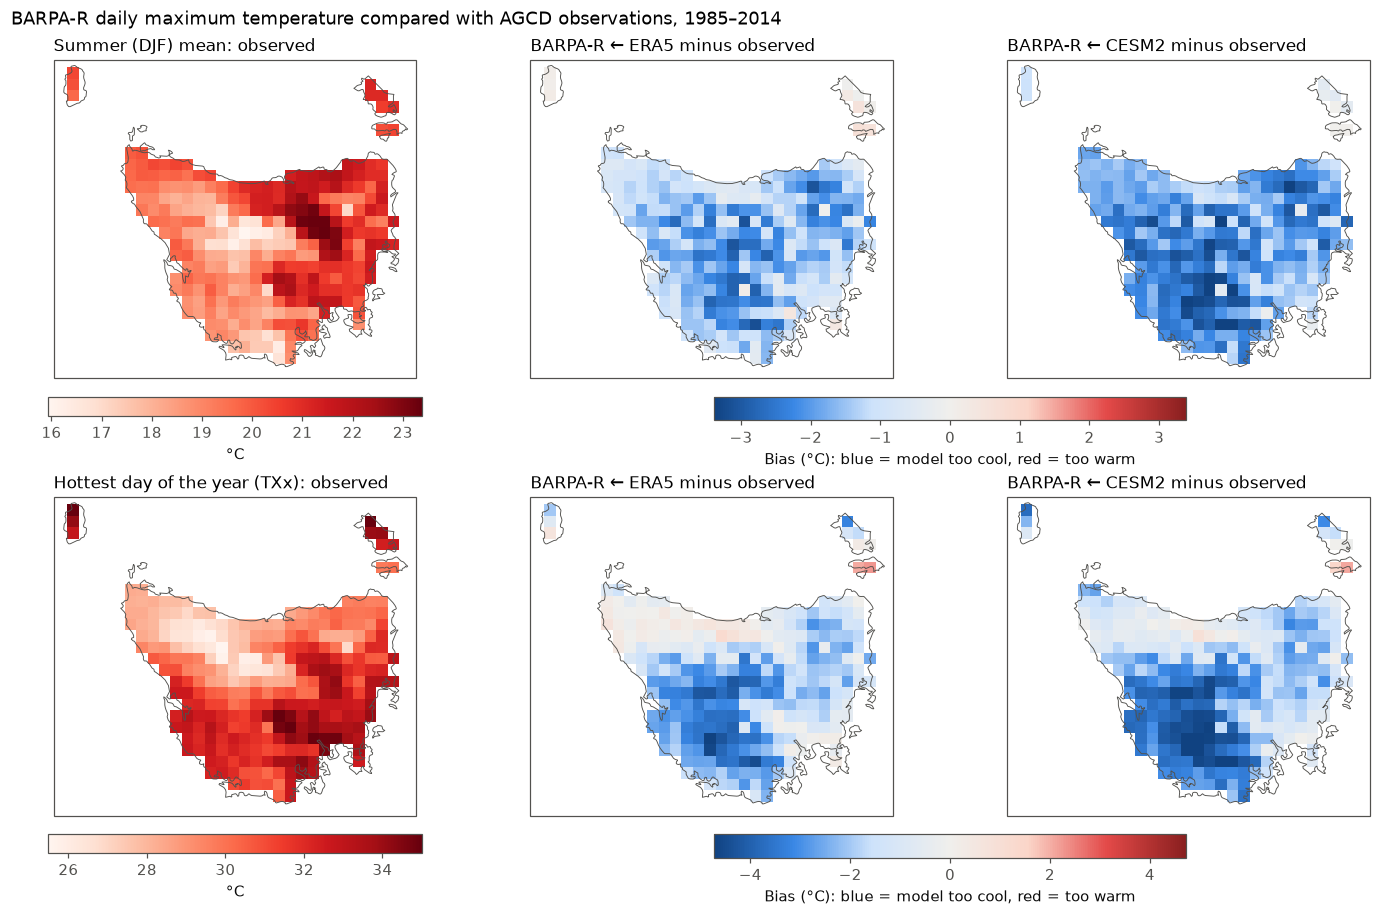

In [5]:
shown = ["Summer (DJF) mean", "Hottest day of the year (TXx)"]
fig, axes = plt.subplots(2, 3, figsize=(13, 8.2), subplot_kw={"projection": ccrs.PlateCarree()},
                         layout="constrained")
for row, name in zip(axes, shown):
    obs_value = measures["Observed"][name].where(compare)
    mesh = row[0].pcolormesh(obs_value.lon, obs_value.lat, obs_value, transform=ccrs.PlateCarree(),
                             cmap="Reds", shading="auto")
    map_panel(row[0], f"{name}: observed")
    fig.colorbar(mesh, ax=row[0], orientation="horizontal", shrink=0.8, label="°C")

    biases = {run: (measures[run][name] - measures["Observed"][name]).where(compare)
              for run in ["BARPA-R ← ERA5", "BARPA-R ← CESM2"]}
    limit = max(float(abs(b).quantile(0.98)) for b in biases.values())
    for ax, (run, bias) in zip(row[1:], biases.items()):
        mesh = ax.pcolormesh(bias.lon, bias.lat, bias, transform=ccrs.PlateCarree(),
                             cmap=BIAS_CMAP, vmin=-limit, vmax=limit, shading="auto")
        map_panel(ax, f"{run} minus observed")
    fig.colorbar(mesh, ax=row[1:], orientation="horizontal", shrink=0.5,
                 label="Bias (°C): blue = model too cool, red = too warm")
fig.suptitle(f"BARPA-R daily maximum temperature compared with AGCD observations, {BASELINE}",
             x=0.01, ha="left", fontsize=12)
fig.savefig(FIG_DIR / "07_tasmania_bias_maps.png")
plt.show()

**What the evaluation shows**

* **The regional model on its own runs cool.** Driven by ERA5, BARPA-R's daily maximums average 1.2–1.7 °C below AGCD across Tasmania. The gap is largest for the hottest day of the year (−1.7 °C). This matches the cold bias across southern Australia reported by Howard et al. (2024).
* **CESM2 adds more cold bias.** Driven by CESM2, the bias grows to between −1.9 and −2.4 °C. So about 0.5–1.3 °C of the error comes from the global model's present-day climate, on top of the regional model's own error.
* **The bias isn't uniform.** For the hottest day of the year, the error is largest in the south-west and the Central Highlands (often 3 °C or more too cool) and close to zero along parts of the north coast. A single statewide correction would therefore be misleading.
* **A cool present doesn't mean a cool future.** CESM2 warms strongly in response to greenhouse gases, yet its present-day Tasmanian maximums are too cool. Present-day bias and future warming are separate questions, so both have to be checked.

**How the rest of the notebook deals with this.** Because the absolute temperatures are biased, the projections below focus on *changes* relative to the model's own 1985–2014 climate (warming, days above the model's own 95th percentile, changes in the 50-year level). Those measures cancel a bias that stays constant over time. Where absolute numbers are useful (section 6), the observed baseline is shifted by the model's projected change: the "delta" method.

## 4 · How much warmer do Tasmanian days get?

In [6]:
baseline_mean = window(historical, BASELINE).mean("time")
warming = {scen: {name: (window(run, name).mean("time") - baseline_mean).where(land) for name in FUTURE}
           for scen, run in cesm2_runs.items()}

pd.DataFrame({
    scen: {name: float(hr.regional_mean(change, land)) for name, change in changes.items()}
    for scen, changes in warming.items()
}).rename_axis("Window").round(2).add_suffix(" ΔTmax (°C)")

,SSP1-2.6 ΔTmax (°C),SSP3-7.0 ΔTmax (°C)
Window,,
2021–2050,1.29,1.42
2041–2070,1.45,2.29
2071–2100,2.06,3.93


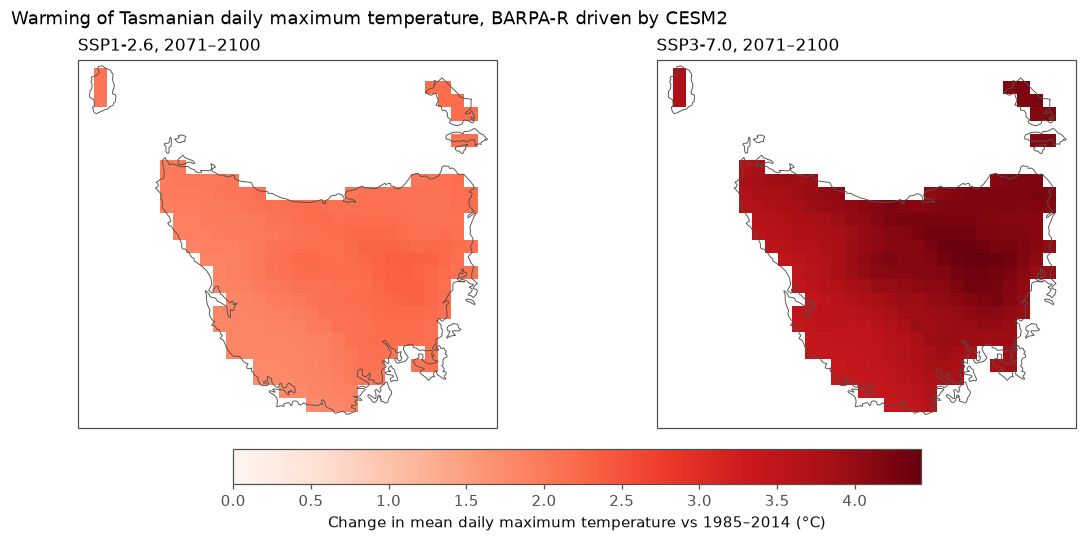

In [7]:
late = {scen: changes["2071–2100"] for scen, changes in warming.items()}
vmax = max(float(change.max()) for change in late.values())
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.8), subplot_kw={"projection": ccrs.PlateCarree()},
                         layout="constrained")
for ax, (scen, change) in zip(axes, late.items()):
    mesh = ax.pcolormesh(change.lon, change.lat, change, transform=ccrs.PlateCarree(),
                         cmap="Reds", vmin=0, vmax=vmax, shading="auto")
    map_panel(ax, f"{scen}, 2071–2100")
fig.colorbar(mesh, ax=axes, orientation="horizontal", shrink=0.6,
             label=f"Change in mean daily maximum temperature vs {BASELINE} (°C)")
fig.suptitle("Warming of Tasmanian daily maximum temperature, BARPA-R driven by CESM2",
             x=0.01, ha="left", fontsize=12)
fig.savefig(FIG_DIR / "08_tasmania_warming.png")
plt.show()

## 5 · How often are days unusually hot?

The threshold is each cell's 95th percentile of daily maximum temperature in the model's own 1985–2014 climate. By construction that is about 18 days a year at the start. Because the threshold comes from the model itself, a constant bias does not affect the count.

In [8]:
p95 = window(historical, BASELINE).quantile(0.95, dim="time").drop_vars("quantile")
hot_days = {scen: hr.regional_mean(hr.annual_exceedance_days(run, p95), land) for scen, run in cesm2_runs.items()}

pd.DataFrame({
    scen: {name: float(window(series, name).mean()) for name in WINDOWS} for scen, series in hot_days.items()
}).rename_axis("Window").round(1).add_suffix(" days/year")

,SSP1-2.6 days/year,SSP3-7.0 days/year
Window,,
1985–2014,18.3,18.3
2021–2050,29.9,31.3
2041–2070,31.0,41.2
2071–2100,36.7,65.9


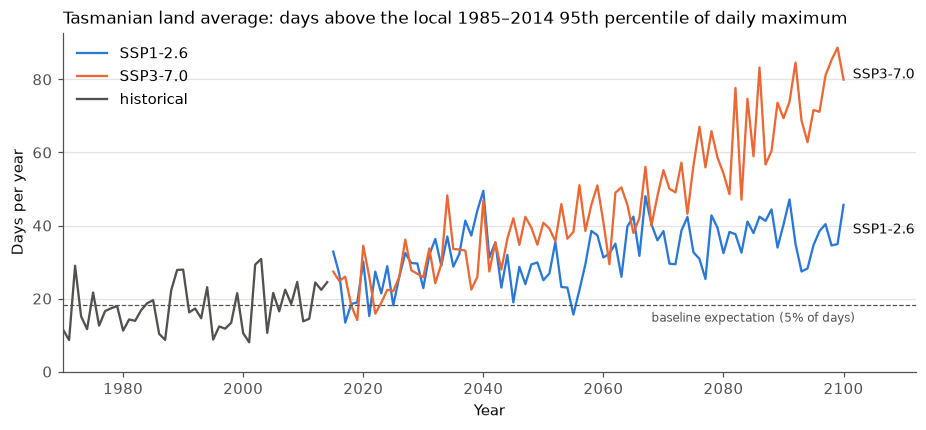

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
for scen, series in hot_days.items():
    future = series.sel(time=slice("2015", None))
    ax.plot(future.time.dt.year, future, color=SCENARIO_COLOURS[scen], label=scen)
    ax.annotate(scen, (2100, float(future[-5:].mean())), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK)
past = hot_days["SSP3-7.0"].sel(time=slice(None, "2014"))
ax.plot(past.time.dt.year, past, color=INK_MUTED, label="historical")
ax.axhline(0.05 * 365, color=INK_MUTED, linewidth=0.8, linestyle="--")
ax.annotate("baseline expectation (5% of days)", (2068, 0.05 * 365), xytext=(0, -11),
            textcoords="offset points", fontsize=8, color=INK_MUTED)
ax.set_xlim(1970, 2112)
ax.set_ylim(0, None)
ax.set_title("Tasmanian land average: days above the local 1985–2014 95th percentile of daily maximum")
ax.set_xlabel("Year")
ax.set_ylabel("Days per year")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y")
fig.savefig(FIG_DIR / "09_tasmania_hot_days.png")
plt.show()

## 6 · The 1-in-50-year hottest day

As in notebook 01, a GEV distribution is fitted to the 30 annual maximums in each window at every land cell, now using daily *maximum* temperature. The table gives the change in the 50-year level, and how often the 1985–2014 50-year day recurs.

In [10]:
annual_max = {scen: hr.annual_maximum(run.where(land)) for scen, run in cesm2_runs.items()}
baseline_gev = hr.gev_parameters(window(annual_max["SSP3-7.0"], BASELINE))
baseline_level = hr.return_level_field(baseline_gev, 50)

rows = []
for scen, amax in annual_max.items():
    for name in FUTURE:
        gev = hr.gev_parameters(window(amax, name))
        rows.append({
            "Scenario": scen, "Window": name,
            "Change in 50-yr level (°C)": float(hr.regional_mean(hr.return_level_field(gev, 50) - baseline_level, land)),
            "1985–2014 50-yr day recurs every (years, median cell)": float(hr.return_period_field(gev, baseline_level).median()),
        })
extremes = pd.DataFrame(rows).set_index(["Scenario", "Window"])
extremes.round(1)

Change in 50-yr level (°C)  \
Scenario Window                                  
SSP1-2.6 2021–2050                         1.1   
         2041–2070                         1.5   
         2071–2100                         1.4   
SSP3-7.0 2021–2050                         1.0   
         2041–2070                         1.4   
         2071–2100                         3.2   

                    1985–2014 50-yr day recurs every (years, median cell)  
Scenario Window                                                            
SSP1-2.6 2021–2050                                               17.3      
         2041–2070                                               11.0      
         2071–2100                                               13.4      
SSP3-7.0 2021–2050                                               18.0      
         2041–2070                                                9.8      
         2071–2100                                                3.1

### Reference places, with observation-anchored values

For each place, the table below combines three numbers:

* the **observed** 1985–2014 50-year level (AGCD, averaged to the 17 km cell);
* the **model's** 1985–2014 50-year level (BARPA-R ← CESM2), which shows the bias at that place;
* an **anchored** future value: the observed baseline plus the model's projected change, for 2071–2100.

The figure shows the model's own 50-year levels with 90% bootstrap intervals, which cover sampling uncertainty only.

In [11]:
place_cells = {place: hr.nearest_land_cell(compare, lat, lon) for place, (lat, lon) in PLACES.items()}

boot_rows, anchored_rows = [], []
observed_amax = hr.annual_maximum(observed)
for place, (lat, lon) in place_cells.items():
    obs_best = float(hr.return_level(hr.fit_gev(observed_amax.sel(lat=lat, lon=lon).values), 50))
    model_base = None
    for scen, amax in annual_max.items():
        series = amax.sel(lat=lat, lon=lon)
        for name in WINDOWS:
            if name == BASELINE and scen != "SSP3-7.0":
                continue  # the baseline is shared by both scenarios
            best, low, high = hr.bootstrap_return_level(window(series, name).values, 50, n_boot=1000)
            boot_rows.append({"Place": place, "Scenario": "historical" if name == BASELINE else scen,
                              "Window": name, "Level": best, "Low": low, "High": high})
            if name == BASELINE:
                model_base = best
    for scen in SCENARIOS:
        late_level = next(r["Level"] for r in boot_rows
                          if r["Place"] == place and r["Scenario"] == scen and r["Window"] == "2071–2100")
        anchored_rows.append({"Place": place, "Cell": f"{lat:.2f}°, {lon:.2f}°", "Scenario": scen,
                              "Observed 1985–2014 (°C)": obs_best, "Model 1985–2014 (°C)": model_base,
                              "Model change by 2071–2100 (°C)": late_level - model_base,
                              "Anchored 2071–2100 (°C)": obs_best + late_level - model_base})

places_boot = pd.DataFrame(boot_rows)
anchored = pd.DataFrame(anchored_rows).set_index(["Place", "Scenario"])
anchored.round(1)

Cell  \
Place                      Scenario                     
Hobart                     SSP1-2.6  -42.91°, 147.36°   
                           SSP3-7.0  -42.91°, 147.36°   
Launceston                 SSP1-2.6  -41.37°, 147.21°   
                           SSP3-7.0  -41.37°, 147.21°   
Strahan (west coast)       SSP1-2.6  -42.14°, 145.35°   
                           SSP3-7.0  -42.14°, 145.35°   
Central Plateau (Liawenee) SSP1-2.6  -41.83°, 146.75°   
                           SSP3-7.0  -41.83°, 146.75°   

                                     Observed 1985–2014 (°C)  \
Place                      Scenario                            
Hobart                     SSP1-2.6                     38.3   
                           SSP3-7.0                     38.3   
Launceston                 SSP1-2.6                     35.3   
                           SSP3-7.0                     35.3   
Strahan (west coast)       SSP1-2.6                     35.8   
                           SSP3-7.0                     35.8   
Central Plateau (Liawenee) SSP1-2.6                     32.4   
                           SSP3-7.0                     32.4   

                                     Model 1985–2014 (°C)  \
Place                      Scenario                         
Hobart                     SSP1-2.6                  40.3   
                           SSP3-7.0                  40.3   
Launceston                 SSP1-2.6                  34.0   
                           SSP3-7.0                  34.0   
Strahan (west coast)       SSP1-2.6                  35.3   
                           SSP3-7.0                  35.3   
Central Plateau (Liawenee) SSP1-2.6                  29.8   
                           SSP3-7.0                  29.8   

                                     Model change by 2071–2100 (°C)  \
Place                      Scenario                                   
Hobart                     SSP1-2.6                            -0.1   
                           SSP3-7.0                             3.2   
Launceston                 SSP1-2.6                             2.5   
                           SSP3-7.0                             3.9   
Strahan (west coast)       SSP1-2.6                             1.0   
                           SSP3-7.0                             3.0   
Central Plateau (Liawenee) SSP1-2.6                             1.3   
                           SSP3-7.0                             1.2   

                                     Anchored 2071–2100 (°C)  
Place                      Scenario                           
Hobart                     SSP1-2.6                     38.2  
                           SSP3-7.0                     41.5  
Launceston                 SSP1-2.6                     37.8  
                           SSP3-7.0                     39.3  
Strahan (west coast)       SSP1-2.6                     36.7  
                           SSP3-7.0                     38.8  
Central Plateau (Liawenee) SSP1-2.6                     33.7  
                           SSP3-7.0                     33.6

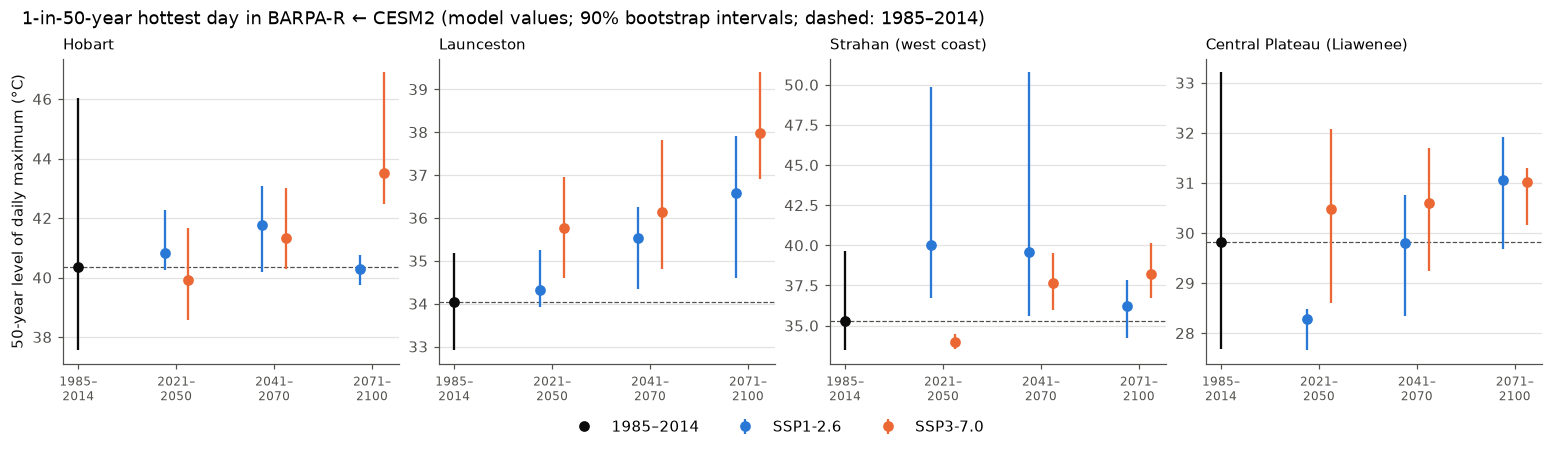

In [12]:
fig, axes = plt.subplots(1, len(PLACES), figsize=(14, 4), sharex=True, layout="constrained")
x = np.arange(len(WINDOWS))
offsets = {"SSP1-2.6": -0.12, "SSP3-7.0": 0.12}
for ax, place in zip(axes, PLACES):
    rows = places_boot[places_boot.Place == place]
    base = rows[rows.Scenario == "historical"].iloc[0]
    ax.errorbar([0], [base.Level], yerr=[[base.Level - base.Low], [base.High - base.Level]],
                fmt="o", markersize=6, color=INK, elinewidth=1.5, capsize=0)
    ax.axhline(base.Level, color=INK_MUTED, linewidth=0.8, linestyle="--")
    for scen, colour in SCENARIO_COLOURS.items():
        sub = rows[rows.Scenario == scen]
        xs = x[1:] + offsets[scen]
        ax.errorbar(xs, sub.Level, yerr=[sub.Level - sub.Low, sub.High - sub.Level],
                    fmt="o", markersize=6, color=colour, elinewidth=1.5, capsize=0, label=scen)
    ax.set_title(place, fontsize=10)
    ax.set_xticks(x, [name.replace("–", "–\n") for name in WINDOWS], fontsize=8)
    ax.grid(axis="y")
axes[0].set_ylabel("50-year level of daily maximum (°C)")
handles, labels = axes[0].get_legend_handles_labels()
handles.insert(0, plt.Line2D([], [], marker="o", color=INK, linestyle="none"))
fig.legend(handles, ["1985–2014", *labels], loc="outside lower center", ncols=3, frameon=False)
fig.suptitle("1-in-50-year hottest day in BARPA-R ← CESM2 (model values; 90% bootstrap intervals; dashed: 1985–2014)",
             x=0.01, ha="left", fontsize=12)
fig.savefig(FIG_DIR / "10_tasmania_places.png")
plt.show()

## 7 · What this shows, and what it can't

**What this one regional simulation shows (BARPA-R driven by CESM2 r11, relative to 1985–2014):**

* **Warming.** Mean daily maximum temperature over Tasmanian land rises by about 2.1 °C by 2071–2100 under SSP1-2.6 and 3.9 °C under SSP3-7.0. The scenarios are similar until about 2050 and then diverge. Warming is strongest in the north-east and the eastern interior and weakest on the south and west coasts.
* **Frequency.** Days above the local 95th percentile rise from 18 a year to about 37 (SSP1-2.6) or 66 (SSP3-7.0) by 2071–2100.
* **Extremes.** Averaged over land, the 1-in-50-year hottest day warms by about 1.4 °C (SSP1-2.6) or 3.2 °C (SSP3-7.0) by 2071–2100. Under SSP3-7.0, the 1985–2014 50-year day comes back roughly every 3 years at the median cell by late century; under SSP1-2.6, roughly every 13 years.
* **Single places are noisy.** At individual 17 km cells, 50-year levels fitted to 30 years jump around. Hobart's SSP1-2.6 value for 2071–2100 is no higher than its baseline, and the Central Plateau shows no difference between scenarios. These are artefacts of one simulation's year-to-year randomness, not real features, and the wide bootstrap intervals say as much. Land averages, which pool hundreds of cells, are far more stable. Reliable place-level numbers need several simulations (notebook 03) or methods that pool information across neighbouring cells.
* **Anchoring to observations matters.** At these places, the model's 1985–2014 50-year level differs from the observed one by up to 2.6 °C, in both directions: too warm at Hobart, too cool on the Central Plateau. Anchored to observations, late-century SSP3-7.0 values are roughly 39–42 °C for Hobart, Launceston and Strahan, and about 34 °C on the plateau. Treat these as illustrative, given the noise described above.

**Bottom line:** BARPA-R gives Tasmania the spatial detail it needs and projects clear increases in heat hazard, much larger under high emissions. But it runs about 2 °C too cool in the present day, so its absolute temperatures shouldn't be used without correction, and single-place extremes from one simulation shouldn't be relied on at all.

### Limitations

| Limitation | Why it matters | Next step |
|---|---|---|
| One driving global model | CESM2 is one of the CMIP6 models with the highest climate sensitivity, and BARPA-R inherits its warming | Repeat with all seven BARPA-R driving models (notebook 03) |
| Regional-model bias | Measured above; relative measures and the delta method only remove a bias that is constant over time | Quantile-mapping bias correction against AGCD |
| Observations are interpolated | AGCD is built from a sparse station network in the west and the highlands, so it smooths extremes there | Compare with individual stations |
| 17 km is still coarse | Valleys, coastal sea breezes and urban heat (e.g. central Hobart) are not resolved | BARPA-C (4 km) exists for limited periods |
| Stationary GEV in 30-year windows | Warming within each window widens the fitted distribution; 50-year levels are extrapolated from 30 years | GEV with a time-varying location parameter |
| Hazard only | Says nothing about exposure or vulnerability | Out of scope: this is a hazard screening |